In [126]:
import torch
import numpy as NP
import matplotlib.pyplot as plt
from torch import nn


dataset = torch.load('./training_set/train-dev_dataset_with_labels.pt')

inputs = dataset[:,:,:-1]
labels = dataset[:, :, -1]

In [127]:
print("Dataset:", dataset.shape)
print("Inputs:", inputs.shape)
print("Labels:", labels.shape)

Dataset: torch.Size([2473, 1, 769])
Inputs: torch.Size([2473, 1, 768])
Labels: torch.Size([2473, 1])


In [128]:
X = inputs.reshape(-1, inputs.shape[-1])
y = labels.reshape(-1).long()

print("Samples:", len(X))
print("Features:", X.shape[1])

print("Classes:", torch.unique(y, return_counts=True))
print("All finite:", torch.isfinite(X).all().item())

Samples: 2473
Features: 768
Classes: (tensor([0, 1, 2, 3, 4, 5, 6]), tensor([319, 232, 397, 400, 394, 364, 367]))
All finite: True


In [129]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [130]:
print("Min:", X.min().item())
print("Max:", X.max().item())
print("Mean:", X.mean().item())
print("Std:", X.std().item())

Min: -0.9777563810348511
Max: 0.9692857265472412
Mean: -0.0010174948256462812
Std: 0.6051807999610901


In [131]:
means = X.mean(dim=0)
stds = X.std(dim=0)

print(means[:10])
print(stds[:10])

tensor([-0.0398,  0.0784, -0.1308,  0.0357, -0.1155, -0.0049,  0.1367, -0.0463,
         0.0374,  0.1666])
tensor([0.4638, 0.5756, 0.5525, 0.5490, 0.5287, 0.5285, 0.5664, 0.5525, 0.5400,
        0.5942])


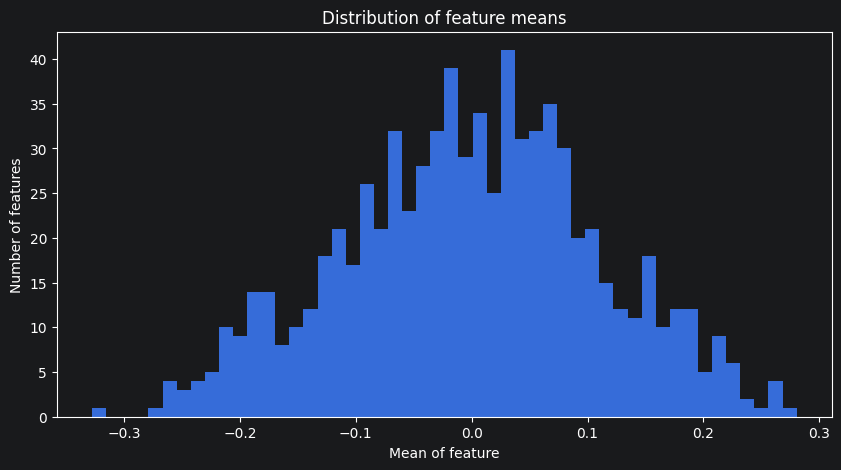

In [132]:
feature_means = X.mean(dim=0).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.hist(feature_means, bins=50)

plt.xlabel("Mean of feature")
plt.ylabel("Number of features")
plt.title("Distribution of feature means")
plt.show()

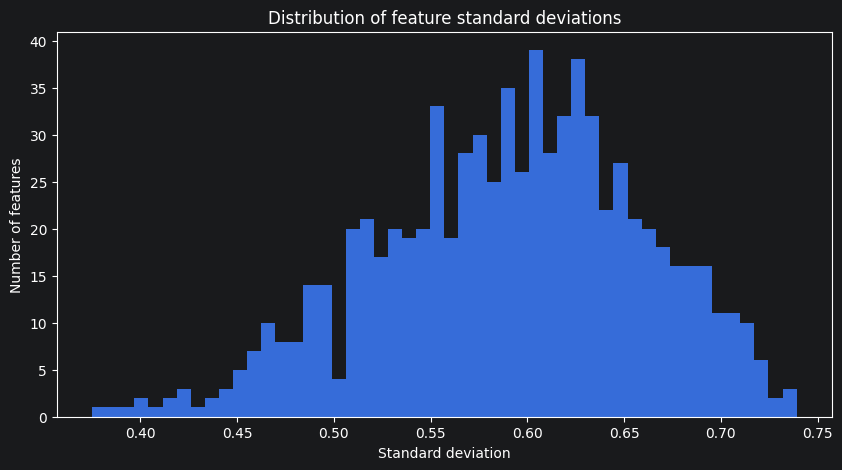

In [133]:
feature_stds = X.std(dim=0).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.hist(feature_stds, bins=50)

plt.xlabel("Standard deviation")
plt.ylabel("Number of features")
plt.title("Distribution of feature standard deviations")
plt.show()

In [134]:
import torch
import random

class SevenWayClassifier():
  def __init__(self, ):
    base_clf = torch.nn.Linear(in_features=768, out_features=5, bias=True)
    base_clf.load_state_dict(torch.load("training_set/base_classifier.pth"))
    self.base_clf = base_clf

  def base_classification(self, input_vector):

    with torch.no_grad():
      logits = self.base_clf(input_vector)
      preds = torch.softmax(logits, 1)
      predicted_class = preds.argmax(dim=1).numpy()[0]

    return predicted_class

  def __call__(self, input_vector):

    random_class = random.choice([0,1,2,3,4,5,6])
    if random_class in [5,6]:
      predicted_class = random_class
    else:
      predicted_class = self.base_classification(input_vector)

    return predicted_class

clf = SevenWayClassifier()

In [135]:
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance"
)

model.fit(X_train_scaled, y_train)

X_test = np.array([[178, 75]])
X_val_scaled = scaler.transform(X_val)

val_predictions = model.predict(X_val_scaled)

In [136]:
from sklearn.metrics import f1_score
print("F1-score:", f1_score(y_val, val_predictions, average="macro"))

F1-score: 0.8591560595580346


In [137]:
router_y_train = np.where(y_train.numpy() < 5, 0, y_train.numpy() - 4)

router_model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance"
)

router_model.fit(X_train.numpy(), router_y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


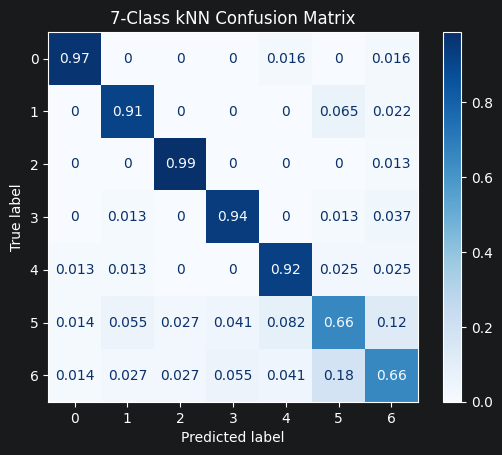

              precision    recall  f1-score   support

           0       0.95      0.97      0.96        64
           1       0.84      0.91      0.88        46
           2       0.95      0.99      0.97        80
           3       0.91      0.94      0.93        80
           4       0.88      0.92      0.90        79
           5       0.72      0.66      0.69        73
           6       0.74      0.66      0.70        73

    accuracy                           0.86       495
   macro avg       0.86      0.86      0.86       495
weighted avg       0.86      0.86      0.86       495



In [146]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=range(7),
    normalize="true",
    cmap="Blues"
)

plt.title("7-Class kNN Confusion Matrix")
plt.show()

print(classification_report(y_val, val_predictions))

In [138]:
class SmartSevenWayClassifier:
    def __init__(self):
        base_clf = torch.nn.Linear(in_features=768, out_features=5, bias=True)
        base_clf.load_state_dict(torch.load("training_set/base_classifier.pth"))
        self.base_clf = base_clf

    def base_classification(self, input_vector):
        with torch.no_grad():
            logits = self.base_clf(input_vector)
            preds = torch.softmax(logits, dim=1)
            predicted_class = preds.argmax(dim=1).item()

        return predicted_class

    def __call__(self, input_vector):
        x = torch.as_tensor(
            input_vector,
            dtype=torch.float32
        ).reshape(1, 768)

        predicted = int(router_model.predict(x.numpy())[0])

        if predicted != 0:
            return predicted + 4

        return self.base_classification(x)

        # random_class = random.choice([0, 1, 2, 3, 4, 5, 6])
        #
        # if random_class in [5, 6]:
        #     predicted_class = random_class
        # else:
        #     predicted_class = self.base_classification(input_vector)
        #
        # return predicted_class

clf = SmartSevenWayClassifier()

In [147]:
cosine_model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance",
    metric="cosine"
)

cosine_model.fit(X_train_scaled, y_train)

pred = cosine_model.predict(X_val_scaled)

print(
    "Macro-F1:",
    f1_score(y_val, pred, average="macro")
)

Macro-F1: 0.8554333547187748


In [139]:
from sklearn.metrics import f1_score

def compute_f1(labels, predictions):
  return f1_score(labels, predictions, average='macro')

In [140]:
from tqdm import tqdm

def inference(clf, input_vectors):
  predictions = []
  for sample in tqdm(input_vectors):
    predictions.append(clf(sample))
  return predictions

In [141]:
predictions = inference(clf, X_val)

f1 = compute_f1(y_val, predictions)

print("Validation Macro F1:", f1)

100%|██████████| 495/495 [00:01<00:00, 278.88it/s]

Validation Macro F1: 0.8559509207344389


In [142]:
predictions = inference(clf, inputs)

f1 = compute_f1(labels, predictions)
print('Naive solution F1', f1)

100%|██████████| 2473/2473 [00:06<00:00, 362.64it/s]

Naive solution F1 0.9629336200574512


In [143]:
# The leaderboard may or may not work... If it doesn't forgive us. We will try to get it running.

import pandas as pd
import numpy as np

def submission_to_csv(pred: np.ndarray, output_fpath: str = "submission.csv"):
    pred = np.array(pred).flatten()
    data_size = pred.size
    df = pd.DataFrame({
        "ID": np.arange(data_size),
        "class": pred
    })

    df.to_csv(output_fpath, index=False)

eval_inputs = torch.load('./Solution/validation_set/eval_dataset.pt')

eval_predictions = inference(clf, eval_inputs)

submission_to_csv(eval_predictions)

100%|██████████| 200/200 [00:00<00:00, 377.75it/s]


In [144]:
# DO NOT CHANGE THIS CELL

# this download link will not work until two hours before the end of the competition
test_inputs = torch.load('Solution/test_set/test_dataset.pt')

split='test'

test_predictions = inference(clf, test_inputs)

with open('{}_predictions.txt'.format("Team Name"), 'w') as outfile:
  outfile.write('\n'.join([str(p) for p in test_predictions]))

100%|██████████| 700/700 [00:01<00:00, 419.36it/s]


In [145]:
pred = np.loadtxt("Team Name_predictions.txt", dtype=int)
assert pred.shape == (700,)
submission_to_csv(pred, "submission_test.csv")